<a href="https://colab.research.google.com/github/DheaAprilya/Pengolahan-Citra-Digital/blob/main/PCD4_DheaAprilya_20240040136_TI24E.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

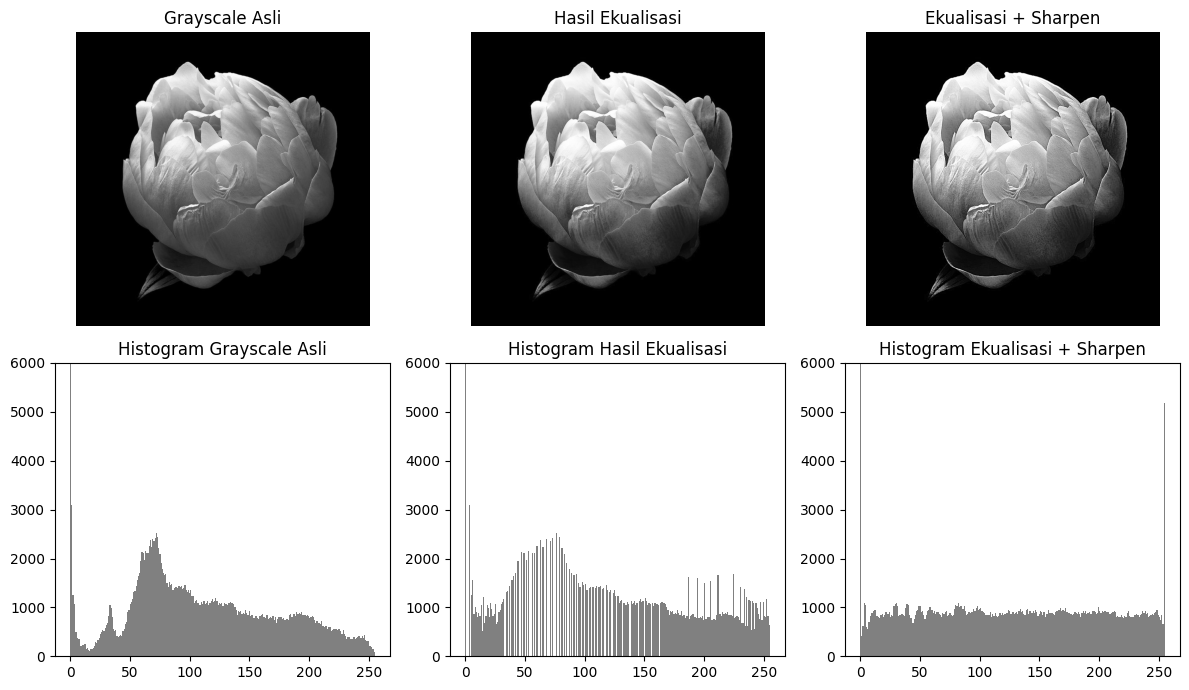

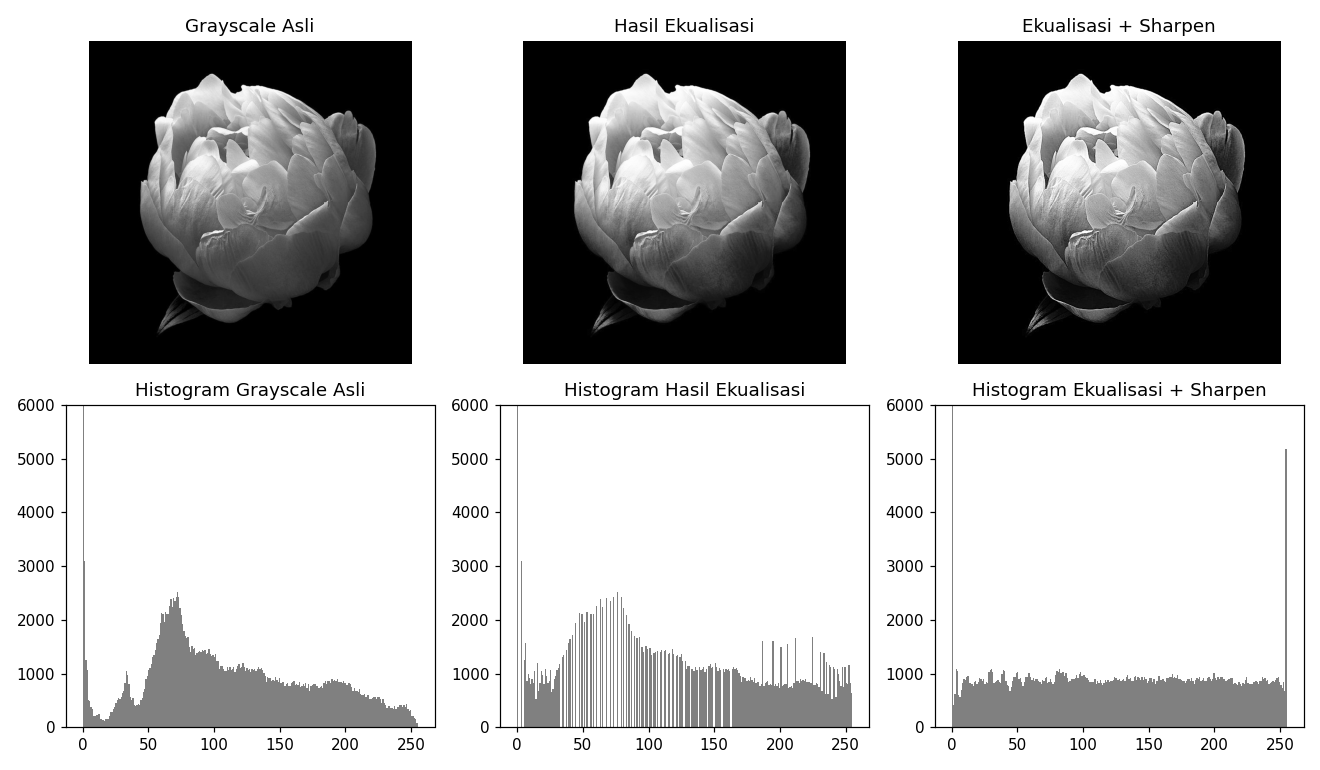

Mean  asli/eq/sharp: 49.6 55.3 55.2
Std   asli/eq/sharp: 69.6 79.7 80.4


In [8]:
import numpy as np
import imageio.v3 as iio
from scipy import ndimage
import matplotlib.pyplot as plt

# Paksa matplotlib menampilkan gambar di notebook (aman kalau bukan notebook)
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    pass

# 1. Baca gambar lalu ubah ke grayscale (rumus luminance)
img = iio.imread("/content/Peonies.jpg").astype(np.float64)
gray = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
gray = np.clip(gray, 0, 255).astype(np.uint8)

# 2. Ekualisasi histogram manual pakai numpy
def equalize(a):
    hist = np.bincount(a.ravel(), minlength=256)   # n_k
    pdf = hist / a.size                            # p(k)
    cdf = np.cumsum(pdf)                           # CDF(k)
    cdf_min = cdf[cdf > 0].min()                   # CDF terkecil yang tidak nol
    lut = np.round(255 * (cdf - cdf_min) / (1 - cdf_min))
    lut = np.clip(lut, 0, 255).astype(np.uint8)    # s_k
    return lut[a]

eq = equalize(gray)

# 3. Sharpening dengan unsharp masking (scipy.ndimage)
blur = ndimage.gaussian_filter(eq.astype(np.float64), sigma=1.5)
sharp = eq + 1.0 * (eq - blur)
sharp = np.clip(sharp, 0, 255).astype(np.uint8)

# 4. Simpan hasil
iio.imwrite("hasil_equalized.png", eq)
iio.imwrite("hasil_sharpen.png", sharp)

# 5. Tampilkan citra dan histogramnya
judul = ["Grayscale Asli", "Hasil Ekualisasi", "Ekualisasi + Sharpen"]
data = [gray, eq, sharp]

fig, ax = plt.subplots(2, 3, figsize=(12, 7))
for i in range(3):
    ax[0, i].imshow(data[i], cmap="gray", vmin=0, vmax=255)
    ax[0, i].set_title(judul[i])
    ax[0, i].axis("off")
    ax[1, i].hist(data[i].ravel(), bins=256, range=(0, 255), color="gray")
    ax[1, i].set_title("Histogram " + judul[i])
    ax[1, i].set_ylim(0, 6000)
plt.tight_layout()
plt.savefig("output_PCD4.png", dpi=110)
plt.show()

# Cadangan: kalau plt.show() tetap tidak menampilkan apa-apa di notebook,
# gambar hasil simpanan ditampilkan langsung dari file
try:
    from IPython.display import Image, display
    display(Image("output_PCD4.png"))
except ImportError:
    pass

print("Mean  asli/eq/sharp:", gray.mean().round(1), eq.mean().round(1), sharp.mean().round(1))
print("Std   asli/eq/sharp:", gray.std().round(1), eq.std().round(1), sharp.std().round(1))